# ScamShield
Explainable SMS phishing detection for financial safety.

This notebook documents an individual Pattern Recognition project. It uses a public SMS benchmark and produces the same model and figures as the Streamlit app. India-focused messages are authored demonstrations, not an independent benchmark. Read `README.md` first.

**Research question:** Do character and structural features improve phishing detection over word features?

**Target:** only `smishing` is positive. `ham` and `spam` are negative under the dataset labels; negative does not mean certified safe.

In [1]:
from pathlib import Path
import os, sys, json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / 'train.py').exists() and (ROOT / 'scamshield' / 'train.py').exists():
    ROOT = ROOT / 'scamshield'
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
print('Project folder:', ROOT)

Project folder: /workspace/scratch/242a44a96318/scamshield


## 1. Inspect the original data
Source: Mishra and Soni (2022), Mendeley DOI `10.17632/f45bkkt8pr.1`, CC BY 4.0. The included CSV comes from the PhishNet research mirror, which describes it as unmodified. We did not verify byte identity against a separate original download.

A DataFrame is a table of rows and columns. Each row is a message. Start by looking at its columns and labels.

In [2]:
raw = pd.read_csv('data/raw.csv')
display(raw.head())
display(raw['LABEL'].str.lower().value_counts().rename('messages').to_frame())
print('Missing text:', raw['TEXT'].isna().sum())

Missing text: 0


,LABEL,TEXT,URL,EMAIL,PHONE
0,ham,Your opinion about me? 1. Over 2. Jada 3. Kusr...,No,No,No
1,ham,What's up? Do you want me to come online? If y...,No,No,No
2,ham,So u workin overtime nigpun?,No,No,No
3,ham,"Also sir, i sent you an email about how to log...",No,No,No
4,Smishing,Please Stay At Home. To encourage the notion o...,No,No,No


,messages
LABEL,
ham,4844
smishing,638
spam,489


## 2. Run the complete experiment
`train.run()` cleans conflicting labels, removes duplicates, creates template groups, splits the data, trains baselines and feature variants, chooses thresholds on validation data, and evaluates the held-out test set.

The training implementation is in `train.py`; shared features are in `core.py`. Read these alongside this notebook. Grouped partitions approximate 60/20/20. Feature vocabularies learn from training messages only. No independent cross-validation performance estimate is claimed.

In [3]:
from train import run
audit, results = run()
display(pd.Series(audit, name="value").to_frame())

{
  "original_rows": 5971,
  "raw_sha256": "649844f1c62a6b27e145eaf17a65f7010c56c390e11a794ea8329993a05ba71e",
  "mirror_url": "https://raw.githubusercontent.com/AbeerAlhuthali/PhishNet/main/PhishNet_Dataset1_original.csv",
  "missing_or_empty_rows": 0,
  "conflicting_binary_text_groups": 34,
  "ambiguous_rows_excluded": 68,
  "duplicate_text_rows_removed": 106,
  "retained_rows": 5797,
  "original_class_counts": {
    "ham": 4844,
    "smishing": 638,
    "spam": 489
  },
  "retained_binary_counts": {
    "0": 5269,
    "1": 528
  },
  "split_counts": {
    "train": {
      "rows": 3477,
      "phishing": 317
    },
    "validation": {
      "rows": 1159,
      "phishing": 105
    },
    "test": {
      "rows": 1161,
      "phishing": 106
    }
  }
}
                        model  precision  recall     f1  false_positive_rate
                      Word NB     0.8750  0.7925 0.8317               0.0114
     Word Logistic Regression     0.9029  0.8774 0.8900               0.0095
       

,value
original_rows,5971
raw_sha256,649844f1c62a6b27e145eaf17a65f7010c56c390e11a79...
mirror_url,https://raw.githubusercontent.com/AbeerAlhutha...
missing_or_empty_rows,0
conflicting_binary_text_groups,34
ambiguous_rows_excluded,68
duplicate_text_rows_removed,106
retained_rows,5797
original_class_counts,"{'ham': 4844, 'smishing': 638, 'spam': 489}"
retained_binary_counts,"{0: 5269, 1: 528}"


## 3. Check the cleaning and splits
Contradictory binary labels are excluded and logged. Repeated exact normalised texts are removed. Links and digit sequences are collapsed only for template grouping. This reduces leakage but does not identify every paraphrased template.

Do not silently change labels to make metrics look better.

In [4]:
splits = {name: pd.read_csv(f'data/{name}.csv') for name in ['train', 'validation', 'test']}
for a, b in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    assert set(splits[a]['group']).isdisjoint(splits[b]['group'])
display(pd.DataFrame(audit['split_counts']).T)
print('Conflicting rows excluded:', audit['ambiguous_rows_excluded'])
print('Repeated text rows removed:', audit['duplicate_text_rows_removed'])

Conflicting rows excluded: 68
Repeated text rows removed: 106


,rows,phishing
train,3477,317
validation,1159,105
test,1161,106


## 4. Understand the data
The class-distribution figure shows why accuracy alone is insufficient. The length distribution describes the sample; it is not proof that a long message is a scam.

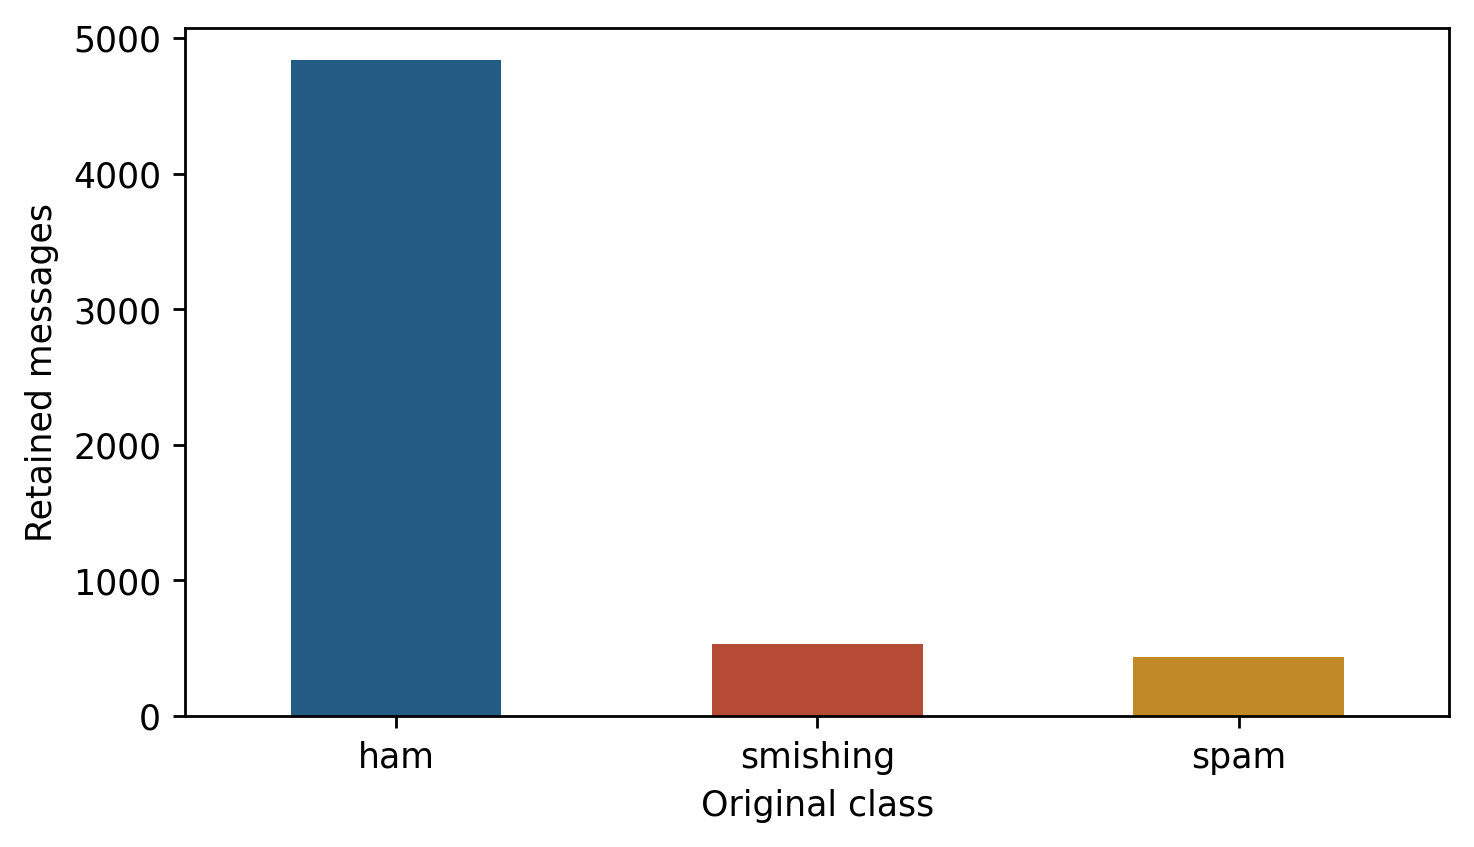

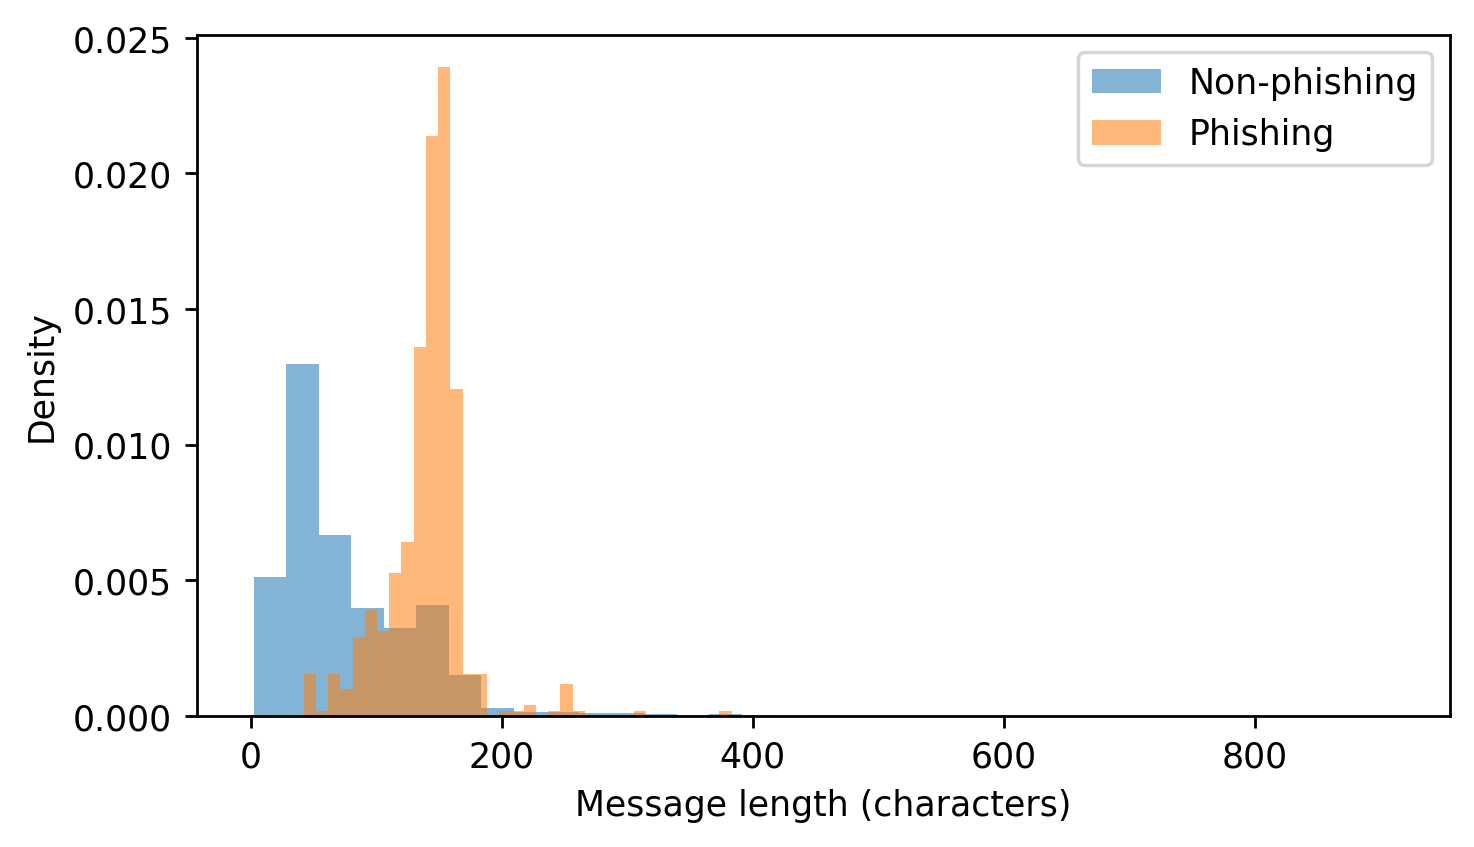

In [5]:
display(Image(filename='outputs/class_distribution.png'))
display(Image(filename='outputs/message_lengths.png'))

## 5. Validation selection
A baseline is a simple method to compare against. An ablation changes the feature representation while keeping the classifier family fixed.

Thresholds maximise phishing F1 on validation messages. The deployed model is selected among Logistic Regression variants by validation F1, with precision breaking ties. Linear SVM and Naive Bayes remain comparison baselines. This selection restriction was made for the interpretable demonstration.

In [6]:
selection = pd.read_csv('outputs/validation_selection.csv')
display(selection.round(4))
metadata = json.loads(Path('outputs/model_metadata.json').read_text())
print('Selected model:', metadata['selected_model'])
print('Warning threshold:', metadata['threshold'])

Selected model: Hybrid Logistic Regression
Warning threshold: 0.62


,model,threshold,validation_f1,validation_precision,validation_recall,fit_seconds
0,Word NB,0.15,0.8571,0.8878,0.8286,0.1128
1,Word Logistic Regression,0.62,0.8744,0.8545,0.8952,0.1058
2,Word SVM,0.25,0.8804,0.8846,0.8762,0.1188
3,Character Logistic Regression,0.66,0.8796,0.8559,0.9048,0.3862
4,Word + Character LR,0.66,0.8807,0.8496,0.9143,0.5852
5,Hybrid Logistic Regression,0.62,0.8860,0.8211,0.9619,0.4933


## 6. Held-out test results
Precision = correct warnings / all warnings. Recall = detected phishing / all labelled phishing. F1 balances them. Average precision summarises the precision–recall relationship.

Report actual results even when a simpler baseline outperforms the proposed enhancement. Test performance must not be used to retroactively choose thresholds.

,model,precision,recall,f1,average_precision,false_positive_rate
0,Word NB,0.8750,0.7925,0.8317,0.9109,0.0114
1,Word Logistic Regression,0.9029,0.8774,0.8900,0.9443,0.0095
2,Word SVM,0.9247,0.8113,0.8643,0.9172,0.0066
3,Character Logistic Regression,0.8889,0.8302,0.8585,0.9396,0.0104
4,Word + Character LR,0.8990,0.8396,0.8683,0.9456,0.0095
5,Hybrid Logistic Regression,0.8440,0.8679,0.8558,0.9426,0.0161
6,Majority baseline,0.0000,0.0000,0.0000,0.0913,0.0000
7,Two-cue rule baseline,0.9412,0.1509,0.2602,0.2196,0.0009


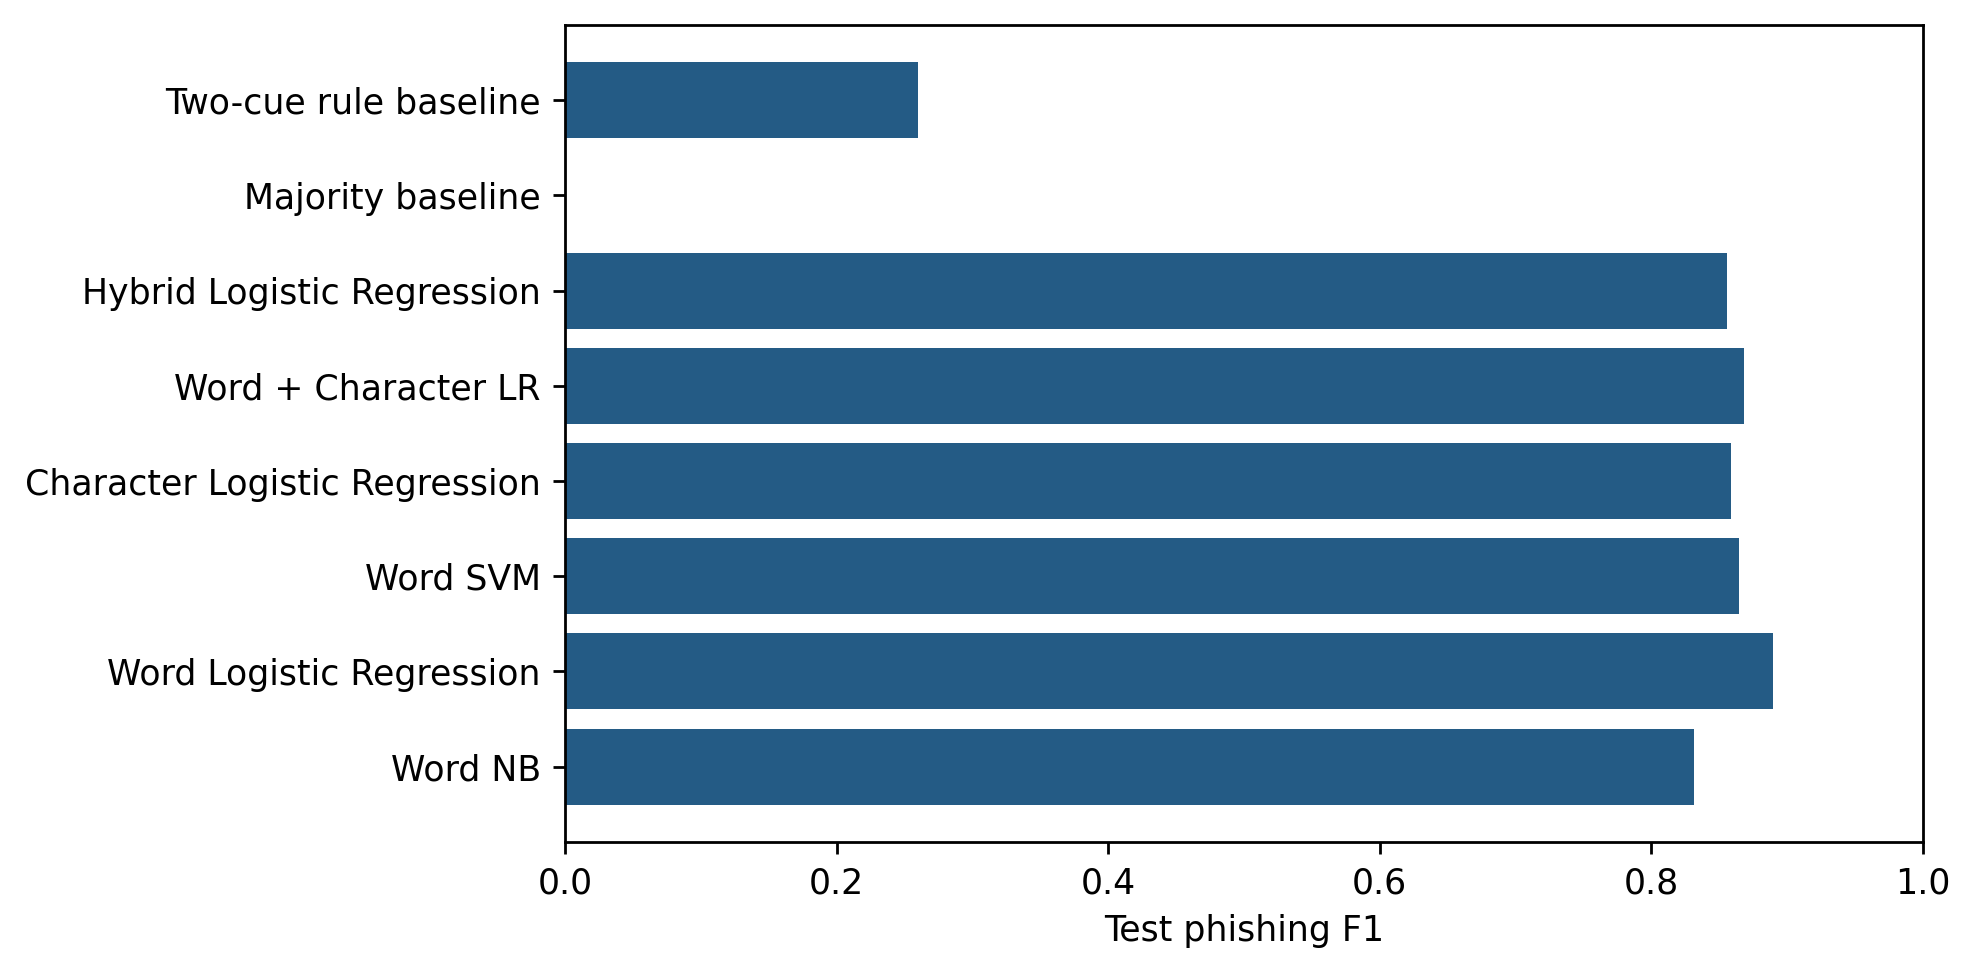

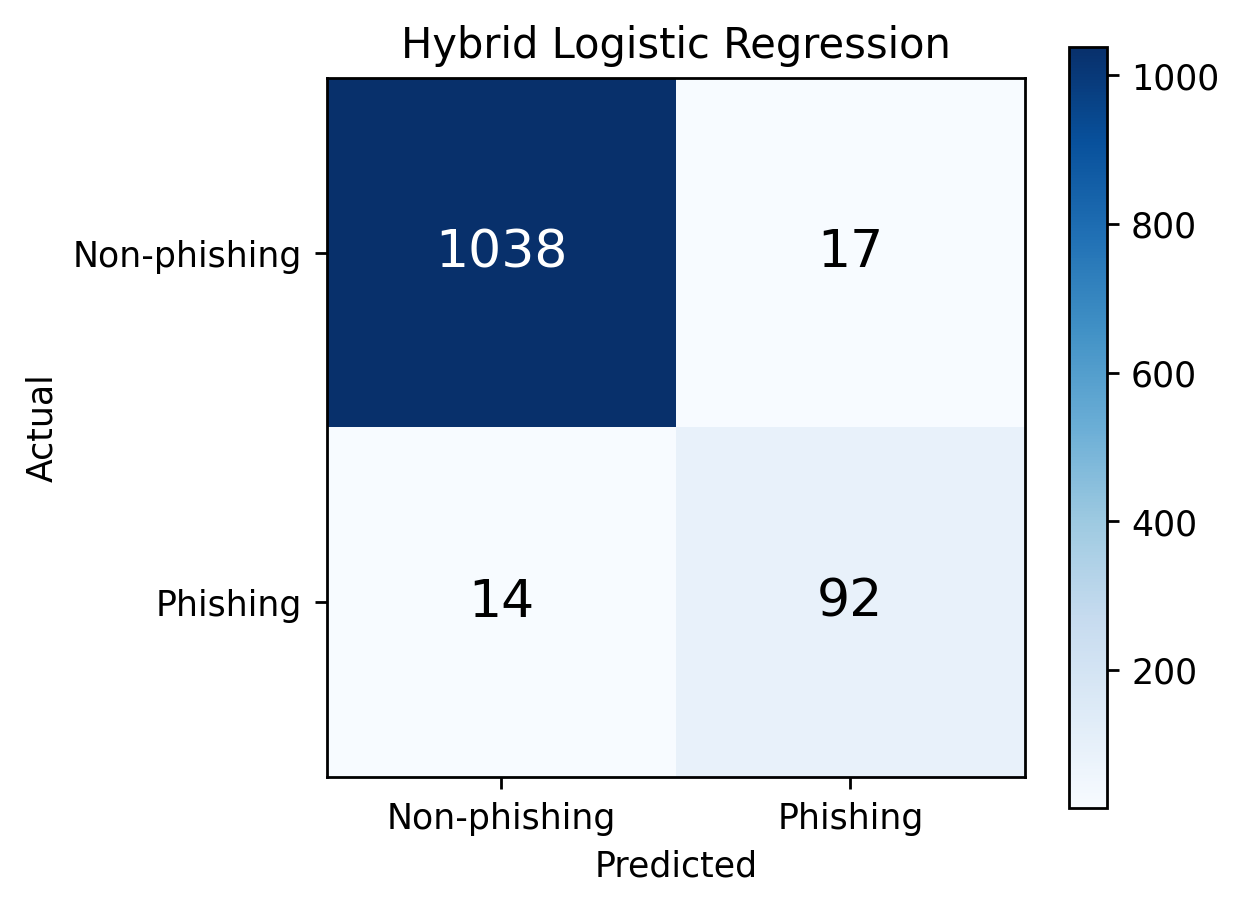

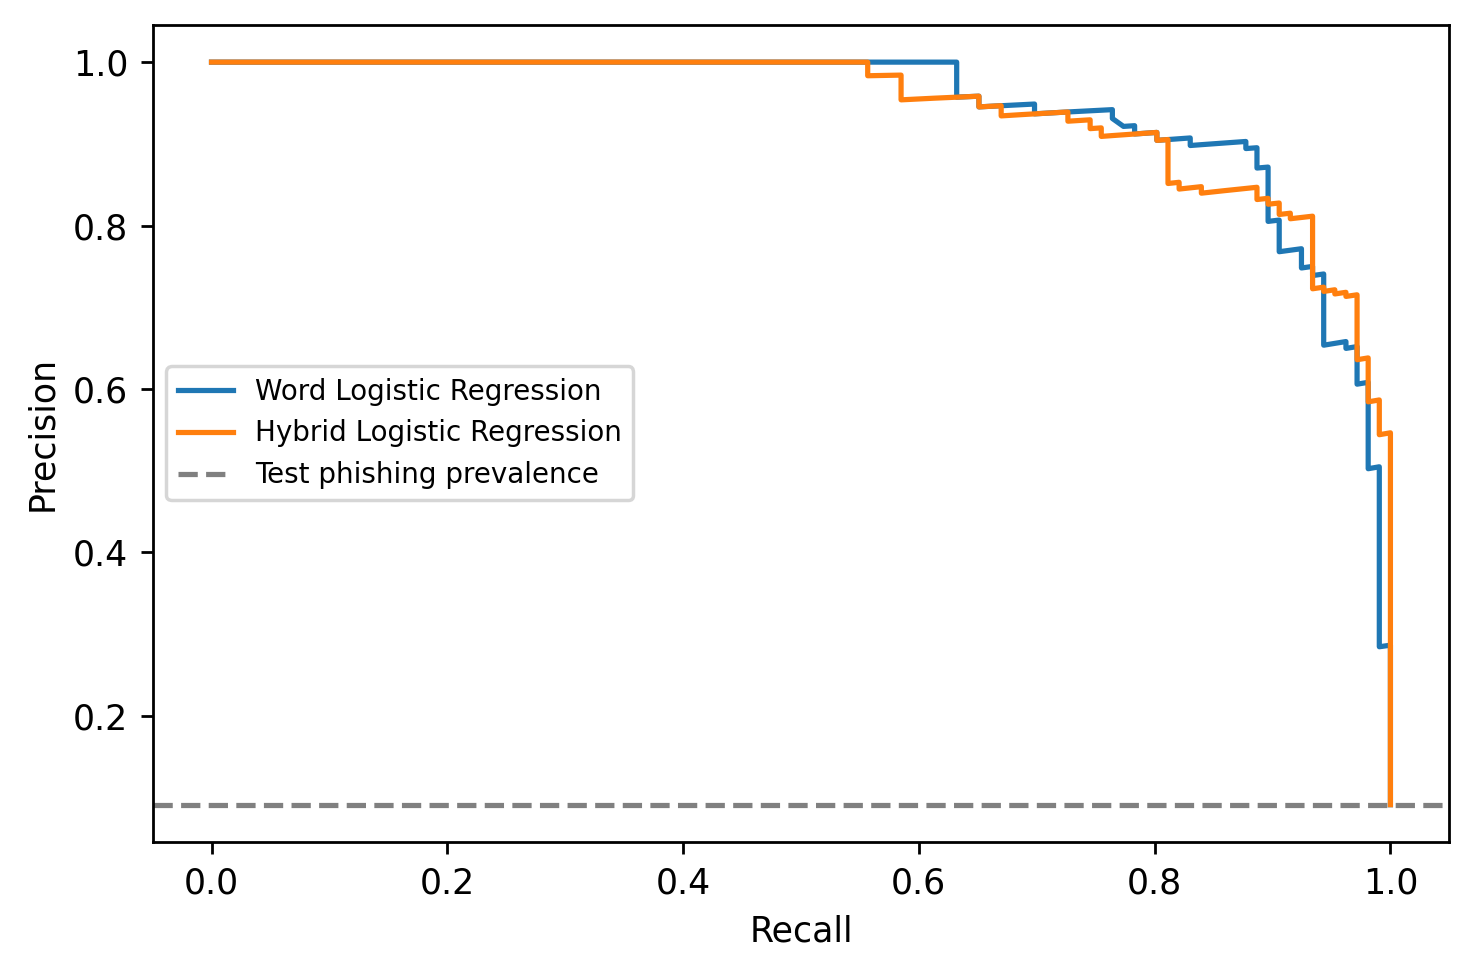

In [7]:
results = pd.read_csv('outputs/test_results.csv')
display(results[['model', 'precision', 'recall', 'f1', 'average_precision', 'false_positive_rate']].round(4))
display(Image(filename='outputs/model_comparison.png'))
display(Image(filename='outputs/confusion_matrix.png'))
display(Image(filename='outputs/precision_recall.png'))

## 7. Analyse errors
False positives are non-phishing messages flagged as phishing. False negatives are phishing messages missed by the detector. Examine both. The warning rate on spam is not the same as detecting financial scams. Avoid clicking any dataset links.

In [8]:
predictions = pd.read_csv('outputs/test_predictions.csv')
display(pd.read_csv('outputs/subtype_warning_rates.csv').round(4))
print('False positives')
display(predictions[(predictions.target == 0) & (predictions.prediction == 1)].head(5))
print('False negatives')
display(predictions[(predictions.target == 1) & (predictions.prediction == 0)].head(5))

False positives
False negatives


,original_label,rows,warning_rate
0,ham,987,0.0020
1,smishing,106,0.8679
2,spam,68,0.2206


,TEXT,original_label,target,score,prediction
67,"Hi, Mobile no. 8623458765 has added you in th...",ham,0,0.752993,1
84,For ur chance to win a £250 wkly shopping spre...,spam,0,0.860535,1
108,Update for FREE to Oranges latest colour camer...,spam,0,0.795879,1
164,Free video camera phones with Half Price line ...,spam,0,0.899169,1
193,Had your mobile 11mths+? You are entitled to u...,spam,0,0.870492,1


,TEXT,original_label,target,score,prediction
1,Please Stay At Home. To encourage the notion o...,smishing,1,0.268560,0
52,YOUR CHANCE TO BE ON A REALITY FANTASY SHOW ca...,smishing,1,0.283289,0
83,\tDo you want 750 anytime any networt NEW vide...,smishing,1,0.617063,0
90,Pvt Finance arranged on cheque basics 4 Busine...,smishing,1,0.112986,0
147,Sorry I missed your call let's talk when you h...,smishing,1,0.184364,0


## 8. Model explanations and Indian demonstration scenarios
Positive feature contributions increase the Logistic Regression logit. Rule cues are displayed separately. A model score is not an independently calibrated probability that the sender is fraudulent.

The examples below are manually authored. They illustrate behaviour and limitations; they are not representative Indian test data.

Separate rule cues: ['Contains a link', 'Language requesting credentials', 'Urgency language', 'Account restriction threat']


,scenario,score,warning,origin
0,KYC account threat,0.982,True,manually authored scenario
1,Prize with advance fee,0.959,True,manually authored scenario
2,Legitimate OTP warning,0.280,False,manually authored scenario
3,Ordinary promotional offer,0.497,False,manually authored scenario
4,Routine payment notification,0.186,False,manually authored scenario
5,UPI credential request,0.862,True,manually authored scenario


,feature,contribution
0,structure__urgency,2.260091
1,structure__url_present,1.621128
2,structure__length,0.355454
3,word__account,0.341953
4,structure__account_threat,0.313114
5,word__your,0.286382
6,word__update,0.145216
7,word__kyc,0.143839


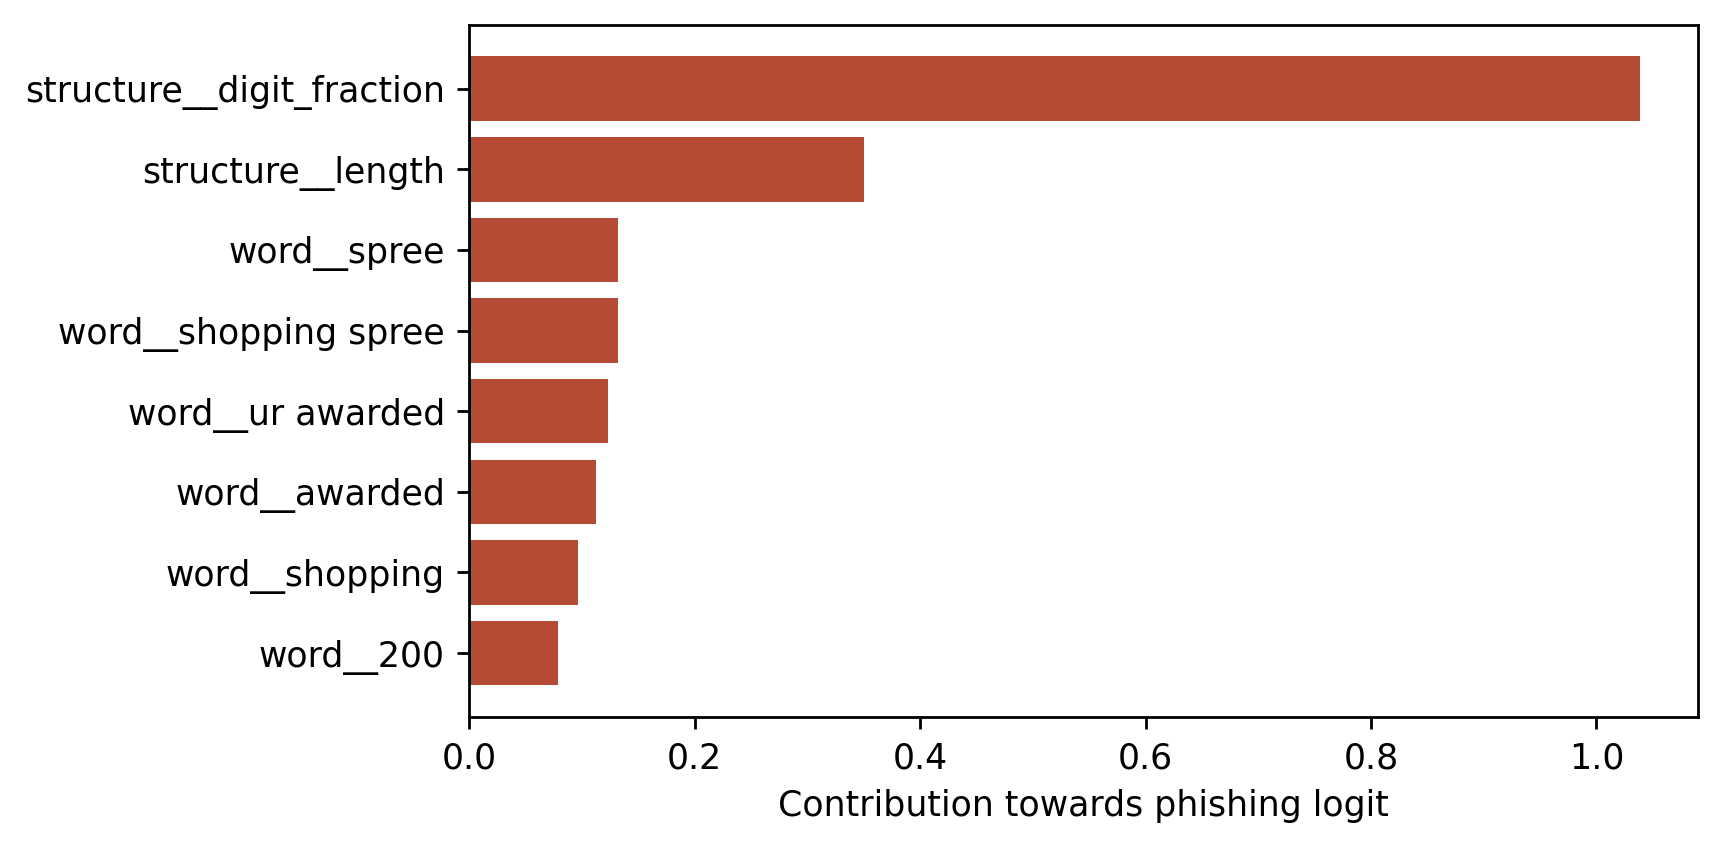

In [9]:
import joblib
from core import explain, warning_cues
bundle = joblib.load('models/scamshield.joblib')
examples = json.loads(Path('data/demo_examples.json').read_text(encoding='utf-8'))
rows = []
for item in examples:
    score = float(bundle['model'].predict_proba([item['text']])[0, 1])
    rows.append({'scenario': item['name'], 'score': score, 'warning': score >= bundle['threshold'], 'origin': item['origin']})
display(pd.DataFrame(rows).round(3))
display(pd.DataFrame(explain(bundle['model'], examples[0]['text'])))
print('Separate rule cues:', warning_cues(examples[0]['text']))
display(Image(filename='outputs/feature_contributions.png'))

## 9. Run the live app
In the VS Code terminal, run:

```powershell
.\.venv\Scripts\python.exe -m streamlit run app.py
```

The app uses the saved pipeline above. Keep this terminal running during the demonstration. Results are displayed locally; the app does not authenticate senders or open links.

## 10. Report and viva
Use tables in `outputs/` and the exported figures. Read `VIVA_GUIDE.md`. Replace identity and guide placeholders in the report, insert screenshots from your own run if required, and complete institutional pages honestly.

**Conclusion to check against the numbers:** the hybrid had higher validation F1 but lower test F1 than word-only Logistic Regression. Added features did not establish a held-out improvement. Performance on current Indian users remains unverified.